# 06 · Root cause analysis with the SCM

**Objective.** For every coolant fault run, rank the candidate variables by how likely they are to be the injected root cause, and compare the ranking with the true manipulated variables.

**Method: SCM-based mechanism-break attribution.** An intervention on a variable replaces its structural equation. A root cause therefore shows values that its own fitted equation cannot explain *given its parents*. Its downstream effects are explained by their (changed) parents. The score of a candidate is its largest surprise $-\log p(x_j[t] \mid x_j[t-1], \mathrm{pa}_j)$ inside the analysis window. This follows the idea of causal anomaly attribution through the noise of structural equations (Budhathoki et al., 2022), in a binary temporal form.

**Task: retrospective incident analysis.** RCA runs once an incident has played out, after the last alarm of the run, using only signals visible on the machine. It explains which variables caused the incident. It is not an online diagnosis at the first alarm. The difference matters in multi-cause scenarios, where some causes are only injected after the first alarm (section 4).

**Evaluation protocol**
- **Leave one scenario out:** the SCM (and, for the discovered graph, the graph itself) is fitted without the scenario whose runs are ranked.
- **Analysis window:** from 60 s before the first alarm onset to 5 s after the last alarm onset of the subsystem.
  - It uses alarms only, which are visible at run time, so it is **label-free**; `causes.json` is never used.
  - Because it ends after the last alarm, it fits the retrospective task, not an online one.
- **Candidates:** non-alarm subsystem variables recorded in the run. Alarms are outcomes, not causes.
- **Ties:** broken by the summed surprise in the window, then by name. Every true cause in coolant reaches the same maximum surprise, so ties among true causes are frequent but never change the metrics.
- **Ground truth:** the `manipulatedVars` of the scenario description (several per run). It is used only to score rankings, and to skip manipulated rows when fitting the mechanisms of *training* runs.
- **Metrics:**
  - Top-1: the first-ranked variable is a true cause.
  - Hit@3: a true cause is in the top 3.
  - Recall@3: share of true causes in the top 3.
  - AP@3 / MAP@3: average precision at 3, averaged over runs.
  - MRR: reciprocal rank of the first true cause.
- **Chance level:** the expected metric of a random ranking of the **same candidates**. The set of recorded variables already narrows down the scenario (notebook 02), so chance is far above zero and every result must be read against it.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

from causal_rca import causal_discovery as cd
from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import graph_evaluation as ge
from causal_rca import preprocessing as pp
from causal_rca import root_cause_analysis as rca
from causal_rca import scm as sc

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
SUBSYSTEM = 'coolant'
INTERVAL = 0.5
SEED = 0
METRICS = ['top1', 'hit@3', 'recall@3', 'ap@3', 'rr']

In [2]:
# data, ground truth and graphs (expert, leave-one-out discovered, empty)
view_data, _ = pp.load_view_data(data.PROCESSED_DIR, f'{SUBSYSTEM}_dt{INTERVAL:g}')
tables = data.RESULTS_DIR / 'tables'
splits = pd.read_csv(tables / f'02_{SUBSYSTEM}_splits.csv')
runs = data.load_fault_runs()
experiments = data.load_experiments()
manipulated = data.manipulated_by_recording(runs, experiments)

expert = ge.simple_digraph(data.load_expert_graph(subsystem=SUBSYSTEM))
NODES = sorted(expert.nodes)
ALARMS = sorted(n for n in NODES if expert.nodes[n]['kind'] == 'Alarm')
edges = pd.read_csv(tables / f'03_{SUBSYSTEM}_edges.csv')
discovered_dag = {gid: ge.to_dag(cd.edges_to_graph(g, NODES))[0] for gid, g in edges.groupby('graph_id')}
empty = nx.DiGraph()
empty.add_nodes_from(NODES)

graph_getters = {
    'expert': lambda fold: expert,
    # the discovered graph of a fold was built without that scenario's regime
    'discovered': lambda fold: discovered_dag[f'discovered_without_{fold}'],
    'empty': lambda fold: empty,
}

## 1. Rankings for every held-out run

In [3]:
# leave-one-scenario-out rca with each graph
results = {}
for name, getter in graph_getters.items():
    metrics, rankings, scms = rca.evaluate_rca(view_data, splits, manipulated, getter, ALARMS, NODES, INTERVAL, seed=SEED)
    results[name] = (metrics, rankings, scms)
    ev.save_table(metrics, f'06_{SUBSYSTEM}_run_metrics_{name}')
    ev.save_table(rankings, f'06_{SUBSYSTEM}_rankings_{name}')
metrics, rankings, scms = results['expert']
print('runs scored:', int(metrics.scored.sum()), 'of', len(metrics))
rankings.assign(ranked=lambda d: d.variable + np.where(d.is_cause, ' *', '')).groupby('recording_id').ranked.apply(' > '.join).to_frame('ranking (expert graph, * = true cause)')

runs scored: 25 of 25


,"ranking (expert graph, * = true cause)"
recording_id,
coolant_exp_22_run_1,HP_Pump_Ok * > LT_Level_Ok * > LT_Pump_Ok > HP...
coolant_exp_22_run_2,HP_Pump_Ok * > LT_Level_Ok * > LT_Pump_Ok > HP...
coolant_exp_22_run_3,HP_Pump_Ok * > LT_Level_Ok * > LT_Pump_Ok > HP...
coolant_exp_22_run_4,HP_Pump_Ok * > LT_Level_Ok * > LT_Pump_Ok > HP...
coolant_exp_22_run_5,HP_Pump_Ok * > LT_Level_Ok * > LT_Pump_Ok > HP...
coolant_exp_22_run_6,HP_Pump_Ok * > LT_Level_Ok * > LT_Pump_Ok > HP...
coolant_exp_27_run_1,CLT_Level_lt_Min * > HP_Pump_Ok * > HP_Pump_is...
coolant_exp_27_run_2,CLT_Level_lt_Min * > HP_Pump_Ok * > HP_Pump_is...
coolant_exp_27_run_3,CLT_Level_lt_Min * > HP_Pump_Ok * > HP_Pump_is...


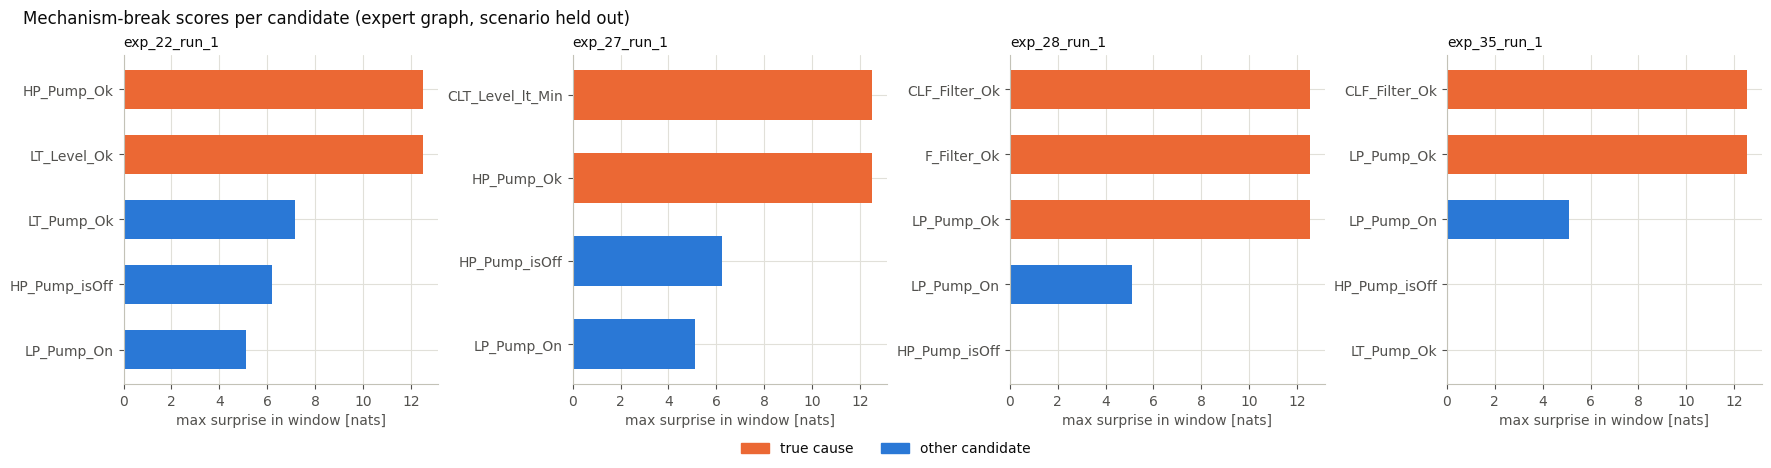

In [4]:
# figure 1: candidate scores in one run of every held-out scenario (expert graph)
folds = sorted(metrics.fold.unique())
fig, axes = plt.subplots(1, len(folds), figsize=(4.4 * len(folds), 4.6), layout='constrained')
for ax, fold in zip(axes, folds):
    rid = metrics.loc[metrics.fold == fold, 'recording_id'].iloc[0]
    r = rankings[rankings.recording_id == rid].sort_values('rank')
    ax.barh(r.variable, r.score, color=[ev.COLORS[1] if c else ev.COLORS[0] for c in r.is_cause], height=0.6)
    ax.invert_yaxis()
    ax.set_xlabel('max surprise in window [nats]')
    ax.set_title(f'{rid.removeprefix(SUBSYSTEM + "_")}', fontsize=10)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ev.COLORS[1], label='true cause'),
                    plt.Rectangle((0, 0), 1, 1, color=ev.COLORS[0], label='other candidate')],
           loc='outside lower center', ncol=2)
fig.suptitle('Mechanism-break scores per candidate (expert graph, scenario held out)', x=0.01, ha='left')
ev.save_figure(fig, f'06_{SUBSYSTEM}_example_rankings')
plt.show()

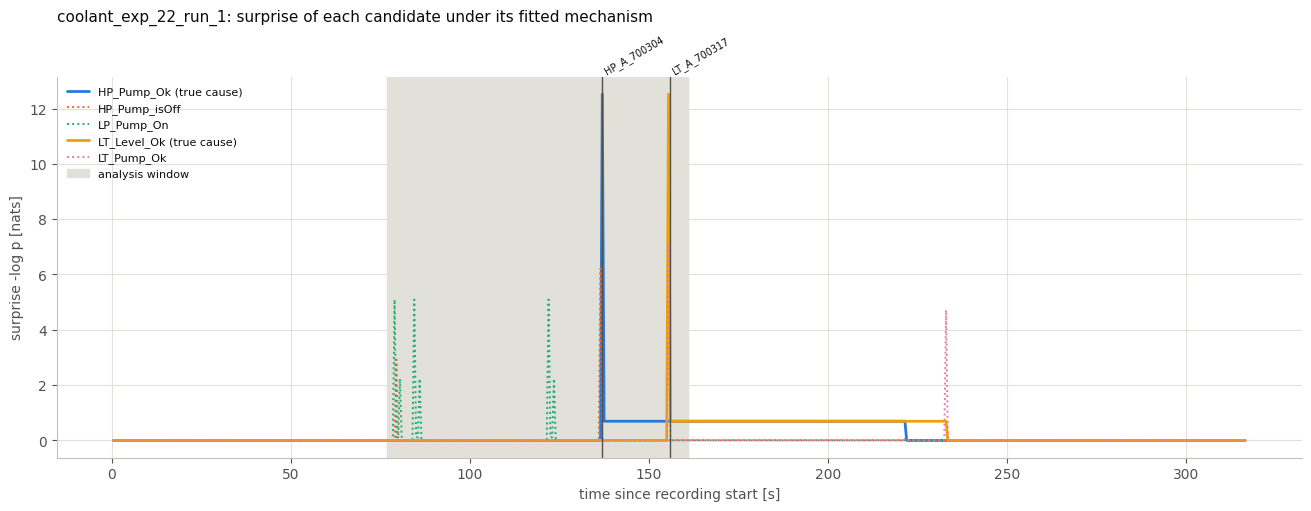

In [5]:
# figure 2: when does each candidate's mechanism break? surprise over time in one run
fold = folds[0]
rid = metrics.loc[metrics.fold == fold, 'recording_id'].iloc[0]
model = scms[fold]
series = sc.recording_series(view_data, rid)
window = rca.analysis_window(series, ALARMS, INTERVAL)
cands = rca.candidates(series, NODES, ALARMS)
t = np.arange(1, len(series[cands[0]])) * INTERVAL
fig, ax = plt.subplots(figsize=(13, 5), layout='constrained')
for k, v in enumerate(cands):
    surprise = model.surprise(series, v)
    style = '-' if v in manipulated[rid] else ':'
    ax.plot(t, surprise, linestyle=style, linewidth=2 if v in manipulated[rid] else 1.4, color=ev.COLORS[k % len(ev.COLORS)],
            label=v + (' (true cause)' if v in manipulated[rid] else ''))
for a, step in rca.alarm_onsets(series, ALARMS).items():
    ax.axvline(step * INTERVAL, color=ev.INK['secondary'], linewidth=1)
    ax.text(step * INTERVAL, 1.01, a, transform=ax.get_xaxis_transform(), rotation=30, fontsize=7)
ax.axvspan(window[0] * INTERVAL, window[1] * INTERVAL, color=ev.INK['grid'], zorder=0, label='analysis window')
ax.set_xlabel('time since recording start [s]')
ax.set_ylabel('surprise -log p [nats]')
ax.set_title(f'{rid}: surprise of each candidate under its fitted mechanism', pad=40)
ax.legend(loc='upper left', fontsize=8)
ev.save_figure(fig, f'06_{SUBSYSTEM}_surprise_timeline')
plt.show()

## 2. Performance against the ground truth and against chance

In [6]:
# mean metrics with bootstrap intervals over runs, per graph
summary = pd.concat([rca.summarize_rca(results[g][0], METRICS, seed=SEED).assign(graph=g) for g in graph_getters],
                    ignore_index=True)
ev.save_table(summary, f'06_{SUBSYSTEM}_summary')
summary.pivot(index='metric', columns='graph', values=['mean', 'chance']).round(3)

mean                  chance              
graph    discovered empty expert discovered  empty expert
metric                                                   
ap@3            1.0   1.0    1.0      0.474  0.474  0.474
hit@3           1.0   1.0    1.0      0.954  0.954  0.954
recall@3        1.0   1.0    1.0      0.643  0.643  0.643
rr              1.0   1.0    1.0      0.695  0.695  0.695
top1            1.0   1.0    1.0      0.467  0.467  0.467

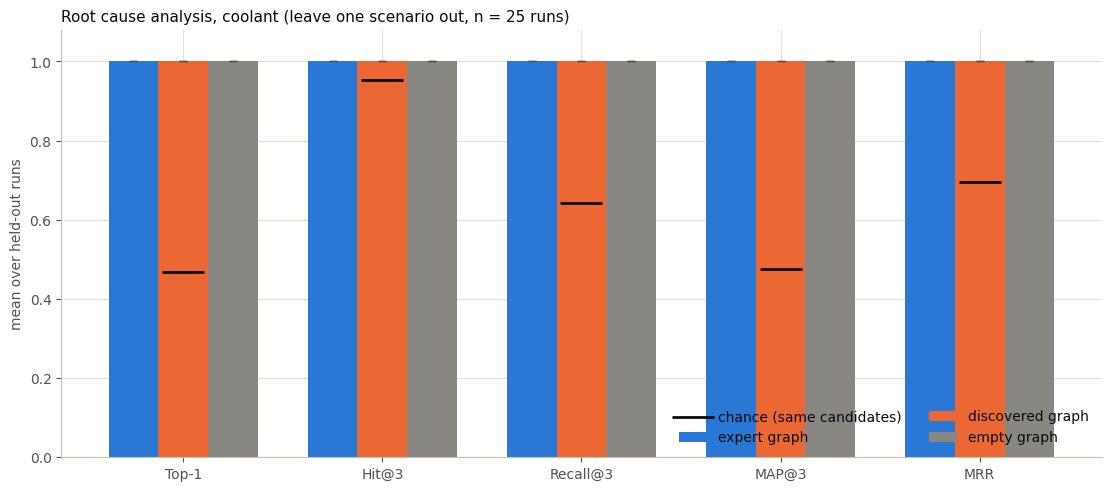

In [7]:
# figure 3: metrics per graph with 95% bootstrap intervals and the chance level
graph_colors = {'expert': ev.COLORS[0], 'discovered': ev.COLORS[1], 'empty': ev.INK['muted']}
fig, ax = plt.subplots(figsize=(11, 4.8), layout='constrained')
x = np.arange(len(METRICS))
for k, g in enumerate(graph_getters):
    s = summary[summary.graph == g].set_index('metric').loc[METRICS]
    ax.bar(x + (k - 1) * 0.25, s['mean'], width=0.25, color=graph_colors[g], label=f'{g} graph',
           yerr=[s['mean'] - s.ci_low, s.ci_high - s['mean']], capsize=3, error_kw={'ecolor': ev.INK['secondary']})
chance = summary[summary.graph == 'expert'].set_index('metric').loc[METRICS, 'chance']
ax.scatter(x, chance, marker='_', s=900, color=ev.INK['primary'], zorder=4, label='chance (same candidates)')
ax.set_xticks(x, ['Top-1', 'Hit@3', 'Recall@3', 'MAP@3', 'MRR'])
ax.set_ylim(0, 1.08)
ax.set_ylabel('mean over held-out runs')
ax.set_title(f'Root cause analysis, {SUBSYSTEM} (leave one scenario out, n = {int(metrics.scored.sum())} runs)')
ax.legend(loc='lower right', ncol=2)
ev.save_figure(fig, f'06_{SUBSYSTEM}_metrics')
plt.show()

In [8]:
# per-scenario performance
per_scenario = pd.concat([
    results[g][0][results[g][0].scored].groupby('fold')[METRICS + ['chance_ap@3']].mean().assign(graph=g)
    for g in graph_getters]).reset_index()
ev.save_table(per_scenario, f'06_{SUBSYSTEM}_per_scenario')
per_scenario.round(3)

,fold,top1,hit@3,recall@3,ap@3,rr,chance_ap@3,graph
0,exp_22,1.0,1.0,1.0,1.0,1.0,0.419,expert
1,exp_27,1.0,1.0,1.0,1.0,1.0,0.555,expert
2,exp_28,1.0,1.0,1.0,1.0,1.0,0.486,expert
3,exp_35,1.0,1.0,1.0,1.0,1.0,0.425,expert
4,exp_22,1.0,1.0,1.0,1.0,1.0,0.419,discovered
5,exp_27,1.0,1.0,1.0,1.0,1.0,0.555,discovered
6,exp_28,1.0,1.0,1.0,1.0,1.0,0.486,discovered
7,exp_35,1.0,1.0,1.0,1.0,1.0,0.425,discovered
8,exp_22,1.0,1.0,1.0,1.0,1.0,0.419,empty
9,exp_27,1.0,1.0,1.0,1.0,1.0,0.555,empty


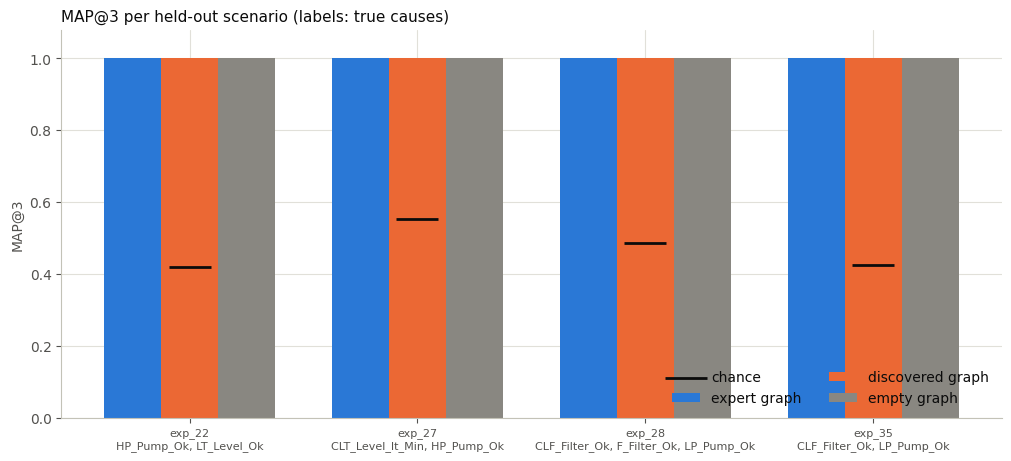

In [9]:
# figure 4: per-scenario map@3 per graph against chance
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
x = np.arange(len(folds))
for k, g in enumerate(graph_getters):
    s = per_scenario[per_scenario.graph == g].set_index('fold').loc[folds]
    ax.bar(x + (k - 1) * 0.25, s['ap@3'], width=0.25, color=graph_colors[g], label=f'{g} graph')
s = per_scenario[per_scenario.graph == 'expert'].set_index('fold').loc[folds]
ax.scatter(x, s['chance_ap@3'], marker='_', s=900, color=ev.INK['primary'], zorder=4, label='chance')
truth_text = [', '.join(sorted(manipulated[metrics.loc[metrics.fold == f, 'recording_id'].iloc[0]])) for f in folds]
ax.set_xticks(x, [f'{f}\n{t}' for f, t in zip(folds, truth_text)], fontsize=8)
ax.set_ylim(0, 1.08)
ax.set_ylabel('MAP@3')
ax.set_title('MAP@3 per held-out scenario (labels: true causes)')
ax.legend(loc='lower right', ncol=2)
ev.save_figure(fig, f'06_{SUBSYSTEM}_per_scenario')
plt.show()

## 3. How clearly are the causes separated?

The **margin** of a run is the score of the weakest true cause minus the score of the strongest non-cause. A positive margin means every true cause ranks above every other candidate. Its size tells how much a graph error would have to shift the scores before the ranking changes.

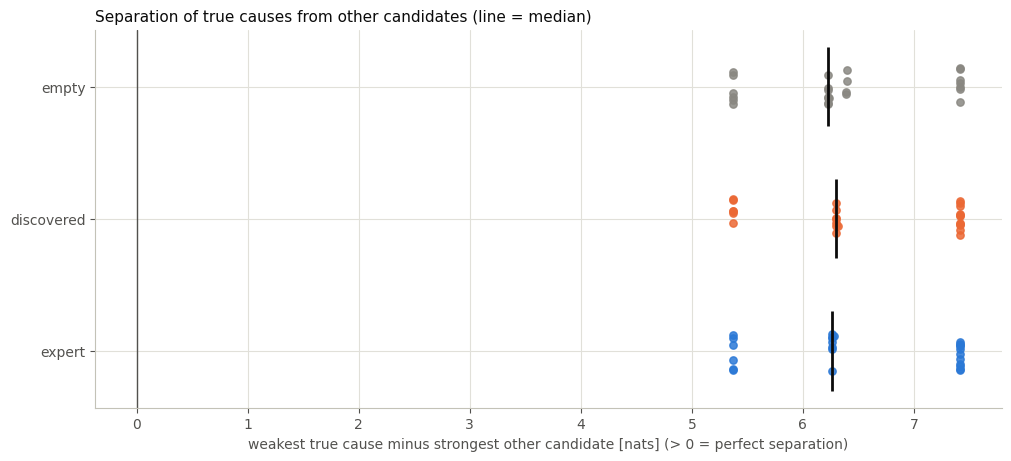

margin                                           weakest_cause                                                strongest_other                                         
            count  mean   std   min   25%   50%   75%   max         count   mean  std    min    25%    50%    75%    max           count  mean   std  min   25%   50%   75%   max
graph                                                                                                                                                                            
discovered   25.0  6.57  0.84  5.37  6.30  6.30  7.41  7.42          25.0  12.52  0.0  12.52  12.52  12.52  12.52  12.52            25.0  5.95  0.84  5.1  5.11  6.22  6.22  7.15
empty        25.0  6.38  0.76  5.37  6.22  6.22  7.41  7.42          25.0  12.52  0.0  12.52  12.52  12.52  12.52  12.52            25.0  6.14  0.76  5.1  5.11  6.30  6.30  7.15
expert       25.0  6.56  0.85  5.37  6.26  6.26  7.42  7.42          25.0  12.52  0.0  12.52  12.52  12.52  12.52  12.52            25.0  5.96  0.85  5.1  5.10  6.26  6.26  7.15

In [10]:
# figure 5: separation margin per run and graph
margin_rows = []
for g in graph_getters:
    r = results[g][1]
    for rid, group in r.groupby('recording_id'):
        causes, others = group[group.is_cause].score, group[~group.is_cause].score
        margin_rows.append({'graph': g, 'recording_id': rid, 'fold': group.fold.iloc[0],
                            'margin': (causes.min() - others.max()) if len(others) else np.nan,
                            'weakest_cause': causes.min(), 'strongest_other': others.max() if len(others) else np.nan})
margins = pd.DataFrame(margin_rows)
ev.save_table(margins, f'06_{SUBSYSTEM}_margins')
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
rng = np.random.default_rng(SEED)
for k, g in enumerate(graph_getters):
    m = margins[margins.graph == g].margin.dropna()
    ax.scatter(m, k + rng.uniform(-0.15, 0.15, len(m)), s=28, color=graph_colors[g], alpha=0.85)
    ax.vlines(m.median(), k - 0.3, k + 0.3, color=ev.INK['primary'], linewidth=2)
ax.axvline(0, color=ev.INK['secondary'], linewidth=1)
ax.set_yticks(range(len(graph_getters)), list(graph_getters))
ax.set_xlabel('weakest true cause minus strongest other candidate [nats] (> 0 = perfect separation)')
ax.set_title('Separation of true causes from other candidates (line = median)')
ev.save_figure(fig, f'06_{SUBSYSTEM}_margins')
plt.show()
margins.groupby('graph')[['margin', 'weakest_cause', 'strongest_other']].describe().round(2)

In [11]:
# paired comparison of graphs on per-run map@3 (wilcoxon signed-rank; ties are common)
ap = pd.DataFrame({g: results[g][0].set_index('recording_id')['ap@3'] for g in graph_getters})
tests = []
for a, b in [('expert', 'discovered'), ('expert', 'empty'), ('discovered', 'empty')]:
    diff = ap[a] - ap[b]
    nonzero = diff[diff != 0]
    p = stats.wilcoxon(nonzero).pvalue if len(nonzero) >= 1 else np.nan
    tests.append({'comparison': f'{a} vs {b}', 'mean_difference': diff.mean(), 'runs_different': len(nonzero), 'wilcoxon_p': p})
paired = pd.DataFrame(tests)
ev.save_table(paired, f'06_{SUBSYSTEM}_paired_tests')
paired

,comparison,mean_difference,runs_different,wilcoxon_p
0,expert vs discovered,0.0,0,NaN
1,expert vs empty,0.0,0,NaN
2,discovered vs empty,0.0,0,NaN


## 4. What drives the scores?

A score is large only when a candidate makes a change its fitted mechanism almost never saw. This section lists, for every candidate, how often it changed in its fold's training data and how many parents it has. It also shows how the alarms of a run are spread in time, which is why the task is defined as retrospective.

In [12]:
# training support of every candidate in its fold's scm, next to its score
diag_rows = []
for g in graph_getters:
    _, r, fold_scms = results[g]
    for row in r.itertuples(index=False):
        mech = fold_scms[row.fold].mechanisms[row.variable]
        diag_rows.append({'graph': g, 'fold': row.fold, 'recording_id': row.recording_id, 'variable': row.variable,
                          'is_cause': row.is_cause, 'n_parents': len(mech.parents),
                          'train_rows': sum(mech.n_rows.values()), 'train_changes': sum(mech.n_changes.values()),
                          'supported': mech.supported, 'score': row.score})
diag = pd.DataFrame(diag_rows)
ev.save_table(diag, f'06_{SUBSYSTEM}_candidate_support')
diag.groupby(['graph', 'is_cause']).agg(
    candidates=('variable', 'size'), mean_parents=('n_parents', 'mean'), mean_train_changes=('train_changes', 'mean'),
    share_unsupported=('supported', lambda s: 1 - s.mean()), min_score=('score', 'min'), max_score=('score', 'max')).round(2)

candidates  mean_parents  mean_train_changes  share_unsupported  min_score  max_score
graph      is_cause                                                                                       
discovered False             62           0.4              840.35                0.0       0.00       7.15
           True              56           0.0                0.00                1.0      12.52      12.52
empty      False             62           0.0              840.35                0.0       0.00       7.15
           True              56           0.0                0.00                1.0      12.52      12.52
expert     False             62           1.4              840.35                0.0       0.00       7.15
           True              56           0.0                0.00                1.0      12.52      12.52

In [13]:
# a parentless variable that never changed in training has p(switch) = 0.5 / (rows + 1) in its smoothed table,
# so its first change scores -log(0.5 / (rows + 1)): the largest surprise the model allows
causes = diag[diag.is_cause].drop_duplicates(['graph', 'fold', 'variable'])
causes.assign(ceiling=lambda d: -np.log(sc.SMOOTHING / (d.train_rows + 1)))[
    ['graph', 'fold', 'variable', 'n_parents', 'train_rows', 'train_changes', 'score', 'ceiling']].round(2)

,graph,fold,variable,n_parents,train_rows,train_changes,score,ceiling
0,expert,exp_22,HP_Pump_Ok,0,136839,0,12.52,12.52
1,expert,exp_22,LT_Level_Ok,0,136839,0,12.52,12.52
30,expert,exp_27,CLT_Level_lt_Min,0,136839,0,12.52,12.52
31,expert,exp_27,HP_Pump_Ok,0,136839,0,12.52,12.52
58,expert,exp_28,CLF_Filter_Ok,0,136839,0,12.52,12.52
59,expert,exp_28,F_Filter_Ok,0,136839,0,12.52,12.52
60,expert,exp_28,LP_Pump_Ok,0,136839,0,12.52,12.52
88,expert,exp_35,CLF_Filter_Ok,0,136839,0,12.52,12.52
89,expert,exp_35,LP_Pump_Ok,0,136839,0,12.52,12.52
118,discovered,exp_22,HP_Pump_Ok,0,136839,0,12.52,12.52


In [14]:
# alarm sequence per run: spread from first to last alarm, and when each true cause first changes
seq_rows = []
for rid, fold in zip(metrics.recording_id, metrics.fold):
    series = sc.recording_series(view_data, rid)
    onsets = rca.alarm_onsets(series, ALARMS)
    if not onsets:
        continue
    first, last = min(onsets.values()), max(onsets.values())
    for c in sorted(manipulated[rid]):
        x = series[c]
        known = ~np.isnan(x[1:]) & ~np.isnan(x[:-1])
        steps = np.flatnonzero(known & (x[1:] != x[:-1])) + 1
        seq_rows.append({'fold': fold, 'recording_id': rid, 'n_alarms': len(onsets),
                         'alarm_spread_s': (last - first) * INTERVAL, 'cause': c,
                         'cause_change_after_first_alarm_s': (steps[0] - first) * INTERVAL if len(steps) else np.nan})
sequence = pd.DataFrame(seq_rows)
ev.save_table(sequence, f'06_{SUBSYSTEM}_alarm_sequence')
per_run = sequence.drop_duplicates('recording_id')
print('alarms per run:', per_run.n_alarms.min(), '-', per_run.n_alarms.max(),
      '| first-to-last alarm spread:', per_run.alarm_spread_s.min(), '-', per_run.alarm_spread_s.max(), 's')
later = sequence[sequence.cause_change_after_first_alarm_s > 0]
print(f'true causes that first change after the first alarm: {len(later)} of {len(sequence)}, '
      f'{later.cause_change_after_first_alarm_s.min()} - {later.cause_change_after_first_alarm_s.max()} s after it')
sequence.groupby(['fold', 'cause']).cause_change_after_first_alarm_s.agg(['min', 'median', 'max'])

alarms per run: 2 - 3 | first-to-last alarm spread: 10.5 - 57.5 s
true causes that first change after the first alarm: 31 of 56, 6.5 - 57.5 s after it


min  median   max
fold   cause                               
exp_22 HP_Pump_Ok        -0.5    0.00   0.0
       LT_Level_Ok       18.5   34.00  57.5
exp_27 CLT_Level_lt_Min  -1.5   -1.00  -1.0
       HP_Pump_Ok        12.0   14.00  17.5
exp_28 CLF_Filter_Ok     -5.5   -5.00  -5.0
       F_Filter_Ok        6.5   13.25  48.5
       LP_Pump_Ok        25.0   41.00  49.5
exp_35 CLF_Filter_Ok     -5.5   -5.50  -5.0
       LP_Pump_Ok        10.0   24.75  31.5

## 5. Findings

- **Performance.** With every graph, every true cause of every held-out run is ranked above every other candidate:

  | Metric | All graphs | Chance (same candidate sets) |
  |---|---|---|
  | Top-1 | 1.00 | 0.47 |
  | Hit@3 | 1.00 | 0.95 |
  | Recall@3 | 1.00 | 0.64 |
  | MAP@3 | 1.00 | 0.47 |
  | MRR | 1.00 | 0.70 |

  These hold for n = 25 runs, 4 held-out scenarios. Hit@3 is close to chance because candidate sets are small (4–5 variables); Top-1, Recall@3 and MAP@3 separate the method from chance clearly.
- **Why every graph scores 1.00** (section 4):
  - **Every true cause is a root node.** It has no parents in the expert, discovered or empty graph, so its score is the same whichever graph is used.
  - **Every true cause never changed in the training data of its fold** (0 changes in 136,839 rows):
    - it is constant in normal operation;
    - its own manipulated runs are skipped when fitting its mechanism (modularity);
    - the other fault scenarios do not record it.
  - Its first change therefore gets the largest surprise the smoothed table allows: −log(0.5 / 136,840) = 12.52 nats. All 56 cause instances score exactly this value, so true causes always tie with each other.
  - Every other candidate changed during training (about 840 times on average) and scores at most 7.15 nats. The margin is 5.4–7.4 nats in every run.
  - On coolant the score therefore works as a "never seen in training" detector. It is correct and label-free, but it says nothing about the graph.
- **What the graph changes.** Only the scores of the non-causes:
  - mean margin 6.38 nats with the empty graph, 6.56 (expert) and 6.57 (discovered), because a parent explains part of a downstream change;
  - no ranking metric changes, and paired tests are not possible because no run differs.
- **Leakage check.** None found:
  - the held-out scenario is excluded from the discovered graph and from SCM fitting;
  - candidates are chosen without labels;
  - the window uses alarms only;
  - the true causes are used only for the metrics and for skipping manipulated training rows.
- **How to classify the 1.00.** An easy setting: injected fault variables are constant in normal operation, the score saturates, and candidate sets are small. It is not an implementation error and not leakage.
- **Why the task is retrospective** (section 4):
  - Coolant runs have 2–3 alarms, 10.5–57.5 s apart from first to last.
  - In multi-cause scenarios the later causes first change 6.5–57.5 s *after* the first alarm.
  - A window ending at the first alarm would count them as misses although they had not happened yet. The window ends after the last alarm because the task is to explain the whole incident.
- **This is a key finding for the thesis.**
  - Coolant RCA is a sanity check of the pipeline. It **cannot discriminate between good and bad graphs**, and it must not be used as evidence that causal discovery improves RCA.
  - Notebook 09 tests this systematically.
  - Notebook 10 provides the discriminating test on the probe subsystem, whose root causes also change in normal operation.
- *Thesis note:*
  - The label-free alarm window and the chance level under the same candidate set are essential to report together with these numbers.
  - The candidate sets are small because each fault run records only its scenario's variables, so 1.00 must be read against 0.47, not against 0.